In [1]:
# ============================================
# REGRESIÓN LINEAL SIMPLE Y MÚLTIPLE
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


In [2]:
# ============================================
# CREACIÓN DEL DATASET
# ============================================

np.random.seed(42)

n = 100

publicidad = np.random.uniform(10, 100, n)
vendedores = np.random.randint(2, 15, n)
clientes = np.random.randint(50, 500, n)

# Generamos las ventas con una relación aproximada
ventas = (
    20
    + 2.5 * publicidad
    + 15 * vendedores
    + 0.8 * clientes
    + np.random.normal(0, 30, n)
)

df = pd.DataFrame({
    "Publicidad": publicidad,
    "Vendedores": vendedores,
    "Clientes": clientes,
    "Ventas": ventas
})

df.head()

,Publicidad,Vendedores,Clientes,Ventas
0,43.708611,8,147,340.842294
1,95.564288,2,247,490.886575
2,75.879455,5,444,598.802505
3,63.879264,14,289,597.744736
4,24.041678,5,193,335.864401


In [3]:
# Cantidad de filas y columnas
print("Filas y columnas:", df.shape)

# Primeras filas
display(df.head(10))

Filas y columnas: (100, 4)


,Publicidad,Vendedores,Clientes,Ventas
0,43.708611,8,147,340.842294
1,95.564288,2,247,490.886575
2,75.879455,5,444,598.802505
3,63.879264,14,289,597.744736
4,24.041678,5,193,335.864401
5,24.039507,6,146,279.710932
6,15.227525,8,250,414.350272
7,87.955853,8,173,514.428433
8,64.100351,14,236,661.083542
9,73.726532,12,375,687.129293


In [4]:
# Tipos de datos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Publicidad  100 non-null    float64
 1   Vendedores  100 non-null    int64  
 2   Clientes    100 non-null    int64  
 3   Ventas      100 non-null    float64
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [5]:
# Estadísticas descriptivas
df.describe()

,Publicidad,Vendedores,Clientes,Ventas
count,100.000000,100.000000,100.00000,100.000000
mean,52.316267,7.860000,291.81000,505.812421
std,26.774047,3.861282,124.70739,130.758875
min,10.496991,2.000000,51.00000,200.369201
25%,27.388068,5.000000,187.75000,430.392789
50%,51.772821,8.000000,285.50000,508.987993
75%,75.718281,11.250000,403.00000,597.760684
max,98.819824,14.000000,494.00000,744.834036


¿Qué variable queremos predecir?

¿Qué variables podrían ayudarnos a explicarla?

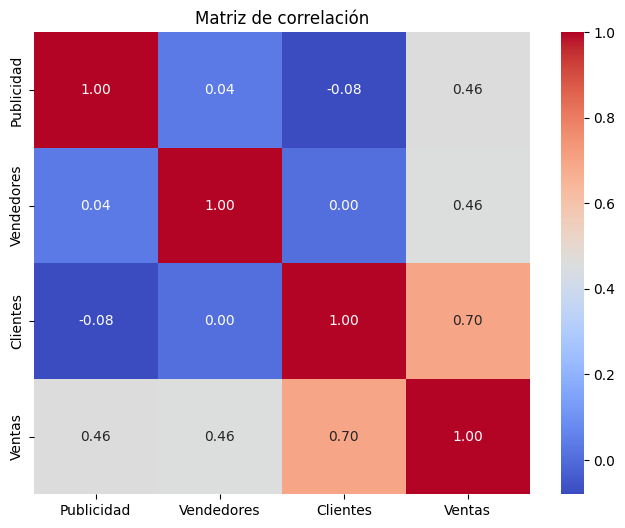

In [6]:
# Matriz de correlación
plt.figure(figsize=(8, 6))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlación")
plt.show()

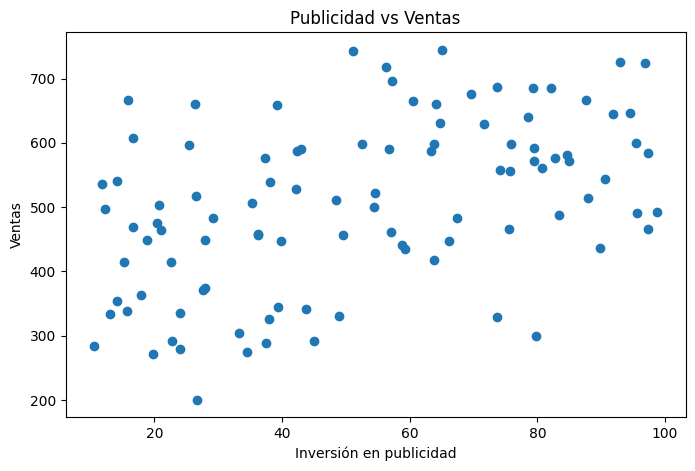

In [7]:
#EDA relación entre publicidad y ventas
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Publicidad"],
    df["Ventas"]
)

plt.xlabel("Inversión en publicidad")
plt.ylabel("Ventas")
plt.title("Publicidad vs Ventas")

plt.show()

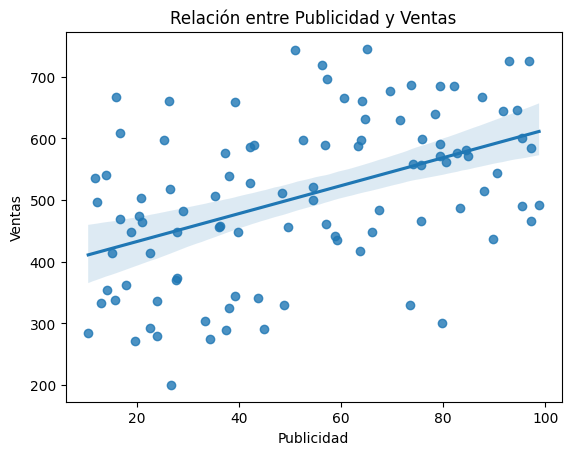

In [8]:
# Linea de tendencia
sns.regplot(
    data=df,
    x="Publicidad",
    y="Ventas"
)

plt.title("Relación entre Publicidad y Ventas")
plt.show()

In [9]:
# ============================================
# REGRESIÓN LINEAL SIMPLE
# ============================================

X = df[["Publicidad"]]
y = df["Ventas"]

# Separar entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (80, 1)
Datos de prueba: (20, 1)


In [10]:
# Entrenar el modelo
modelo_simple = LinearRegression()

modelo_simple.fit(X_train, y_train)

print("Modelo entrenado correctamente")

Modelo entrenado correctamente


In [11]:
# coeficientes del modelo
print("Intercepto:", modelo_simple.intercept_)
print("Coeficiente:", modelo_simple.coef_[0])

Intercepto: 383.1658054432002
Coeficiente: 2.344950828708058


$$\text{Ventas} = 383.17 + 2.34 \times \text{Publicidad}$$
A continuación se detalla la interpretación práctica de cada parámetro:
Coeficiente (Pendiente): 2.34
Qué significa: Por cada unidad monetaria (o de inversión) adicional que destines a publicidad, se espera que tus ventas aumenten en promedio 2.34 unidades, manteniendo todo lo demás constante.

Implicación de negocio: Muestra una relación positiva directa; es el retorno marginal estimado de tus esfuerzos de marketing en función de los datos analizados.Intercepto: 383.16

Qué significa: Es el valor estimado de las ventas cuando la inversión en publicidad es igual a 0.Implicación de negocio: Representa las ventas basales o "ventas autónomas" (aquellas que ocurren por inercia, clientes recurrentes o reconocimiento de marca previo sin invertir en pauta publicitaria).
Ventas = 383.16+ (2.34x100)= 2723.16 unidades



In [12]:
# Hacemos predicciones
y_pred = modelo_simple.predict(X_test)

resultados = pd.DataFrame({
    "Ventas reales": y_test,
    "Ventas predichas": y_pred
})

resultados.head(10)

,Ventas reales,Ventas predichas
83,338.441158,420.029022
53,543.696272,595.464666
70,591.395665,569.594155
45,675.913592,546.437710
44,303.951936,461.229684
39,456.150536,499.507550
22,458.551147,468.271149
80,667.159722,588.769472
10,535.839353,410.959580
0,340.842294,485.660348


In [13]:
# Evaluamos el modelo
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 2))

MAE : 86.71
MSE : 10803.94
RMSE: 103.94
R²  : 0.22


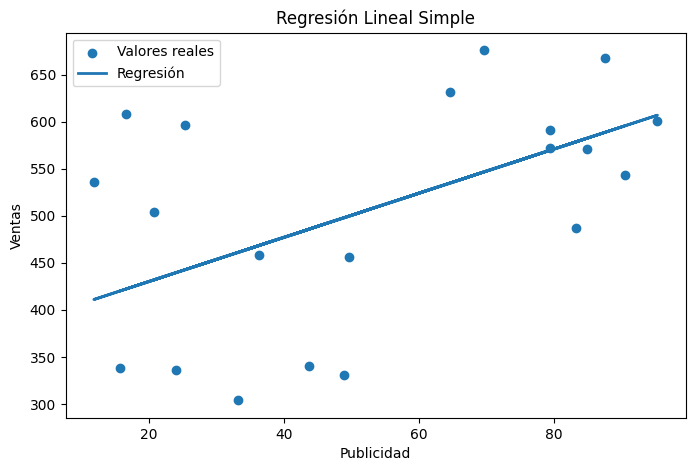

In [14]:
# Visualización de predicciones
plt.figure(figsize=(8, 5))

plt.scatter(X_test, y_test, label="Valores reales")

plt.plot(
    X_test,
    y_pred,
    linewidth=2,
    label="Regresión"
)

plt.xlabel("Publicidad")
plt.ylabel("Ventas")
plt.title("Regresión Lineal Simple")

plt.legend()
plt.show()

In [ ]:
# ============================================
# REGRESIÓN LINEAL MÚLTIPLE
# ============================================

X = df[
    [
        "Publicidad",
        "Vendedores",
        "Clientes"
    ]
]

y = df["Ventas"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

modelo_multiple = LinearRegression()

modelo_multiple.fit(X_train, y_train)

print("Modelo múltiple entrenado correctamente")

Modelo múltiple entrenado correctamente


In [ ]:
# Análisis de coeficientes
coeficientes = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente": modelo_multiple.coef_
})

coeficientes

,Variable,Coeficiente
0,Publicidad,2.467570
1,Vendedores,15.593747
2,Clientes,0.762631


$$\text{Ventas} = \beta_0 + 2.47 \cdot \text{Publicidad} + 15.59 \cdot \text{Vendedores} + 0.76 \cdot \text{Clientes}$$

Interpretación formal de los coeficientes:

Publicidad ($\beta_1 = 2.47$): Por cada unidad adicional invertida en publicidad, las ventas aumentan en promedio $2.47$ unidades, manteniendo constantes la cantidad de vendedores y clientes (ceteris paribus).

Vendedores ($\beta_2 = 15.59$): Por cada vendedor adicional incorporado al equipo, las ventas aumentan en promedio $15.59$ unidades, manteniendo constantes la publicidad y la cantidad de clientes.

Clientes ($\beta_3 = 0.76$): Por cada cliente adicional en la cartera, las ventas aumentan en promedio $0.76$ unidades, manteniendo constantes la publicidad y la cantidad de vendedores.

In [ ]:
# Predicciones
y_pred_multiple = modelo_multiple.predict(X_test)

resultados_multiple = pd.DataFrame({
    "Ventas reales": y_test,
    "Ventas predichas": y_pred_multiple
})

resultados_multiple.head(10)

,Ventas reales,Ventas predichas
83,338.441158,294.764102
53,543.696272,570.908759
70,591.395665,555.948224
45,675.913592,643.868023
44,303.951936,277.710634
39,456.150536,457.471116
22,458.551147,487.297775
80,667.159722,636.975957
10,535.839353,583.007173
0,340.842294,376.631333


El modelo recibió información sobre publicidad, cantidad de vendedores y cantidad de clientes. A partir de esas variables estimó cuánto deberían ser las ventas. La diferencia entre lo que realmente ocurrió y lo que el modelo estimó es el error o residuo.

Matemáticamente:

Error = Valor real − Valor predicho

In [ ]:
# Evaluación del modelo
mae = mean_absolute_error(y_test, y_pred_multiple)
mse = mean_squared_error(y_test, y_pred_multiple)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_multiple)

print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 2))

MAE : 26.05
MSE : 914.86
RMSE: 30.25
R²  : 0.93


MAE = 26,05

Significa que:

En promedio, las predicciones del modelo se alejan aproximadamente 26 unidades del valor real.

RMSE = 30,25

Como:

RMSE > MAE

podemos sospechar que existen algunas predicciones con errores relativamente grandes.

MAE nos dice cuánto nos equivocamos en promedio; RMSE nos da más importancia cuando nos equivocamos mucho.

R² = 0,93
El modelo logra explicar el 93% de la variabilidad observada en las ventas, utilizando las variables incluidas en el modelo.

Podemos decir que el modelo tiene un buen desempeño general, aunque no acierte exactamente cada predicción.

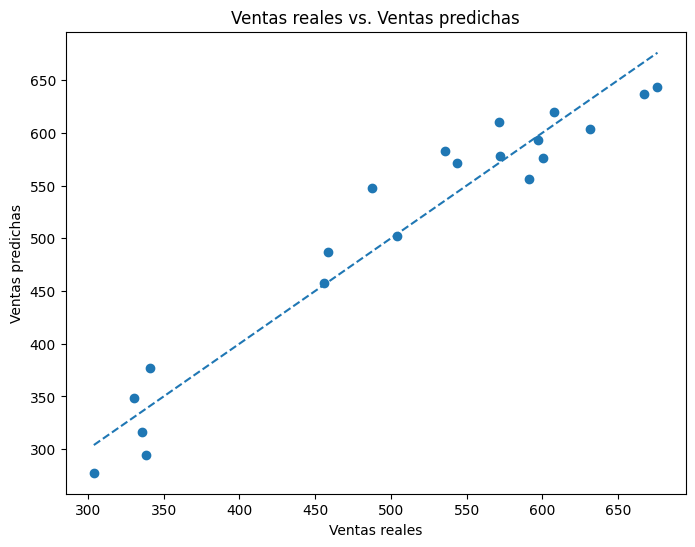

In [ ]:
# Visualización predicciones
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_multiple)

# Línea perfecta: predicción = realidad
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Ventas reales")
plt.ylabel("Ventas predichas")
plt.title("Ventas reales vs. Ventas predichas")

plt.show()

In [ ]:
# Predicciones del modelo simple
pred_simple = modelo_simple.predict(X_test[["Publicidad"]])

# Métricas
r2_simple = r2_score(y_test, pred_simple)
r2_multiple = r2_score(y_test, y_pred_multiple)

rmse_simple = np.sqrt(
    mean_squared_error(y_test, pred_simple)
)

rmse_multiple = np.sqrt(
    mean_squared_error(y_test, y_pred_multiple)
)

comparacion = pd.DataFrame({
    "Modelo": [
        "Regresión simple",
        "Regresión múltiple"
    ],
    "RMSE": [
        rmse_simple,
        rmse_multiple
    ],
    "R²": [
        r2_simple,
        r2_multiple
    ]
})

comparacion

,Modelo,RMSE,R²
0,Regresión simple,103.941993,0.220729
1,Regresión múltiple,30.246628,0.934013
